In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset imported successfully!")
print("Shape:", df.shape)

df.head()

Dataset imported successfully!
Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [4]:
print("Relevant Variables:")

print("Product Categories:")
print(df["Product Category"].unique())

print("\nTotal Amount:")
print(df["Total Amount"].head())

print("\nQuantity:")
print(df["Quantity"].head())

Relevant Variables:
Product Categories:
['Beauty' 'Clothing' 'Electronics']

Total Amount:
0     150
1    1000
2      30
3     500
4     100
Name: Total Amount, dtype: int64

Quantity:
0    3
1    2
2    1
3    1
4    2
Name: Quantity, dtype: int64


In [5]:
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum()

print("Total Sales by Product Category:")
print(category_sales)

Total Sales by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


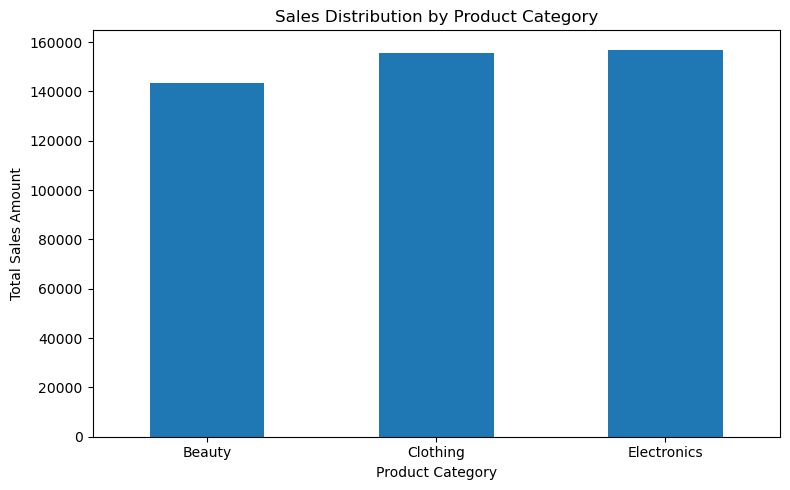

In [6]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.title("Sales Distribution by Product Category")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

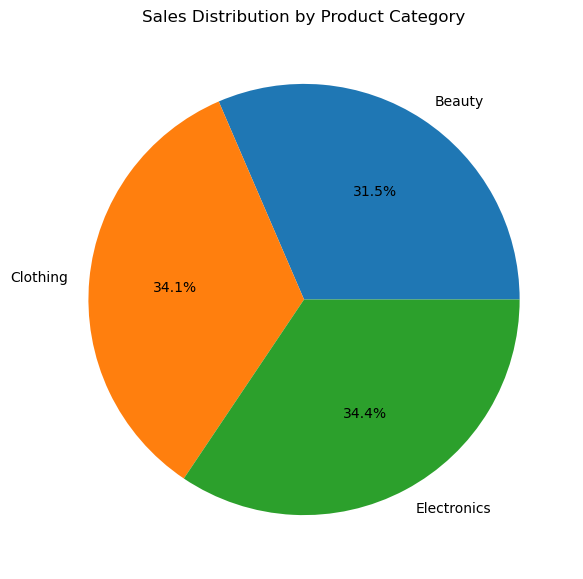

In [7]:
plt.figure(figsize=(7, 7))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%"
)

plt.title("Sales Distribution by Product Category")
plt.show()

In [8]:
category_sales = category_sales.sort_values(
    ascending=False
)

print("Sales Ranking:")
print(category_sales)

print("\nTop-Performing Product Category:")
print(category_sales.index[0])

print("Highest Sales Amount:")
print(category_sales.iloc[0])

Sales Ranking:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Top-Performing Product Category:
Electronics
Highest Sales Amount:
156905


In [9]:
gender_category_sales = df.groupby(
    ["Gender", "Product Category"]
)["Total Amount"].sum().unstack()

print("Sales by Gender and Product Category:")
display(gender_category_sales)

Sales by Gender and Product Category:


Product Category,Beauty,Clothing,Electronics
Gender,,,
Female,74830,81275,76735
Male,68685,74305,80170


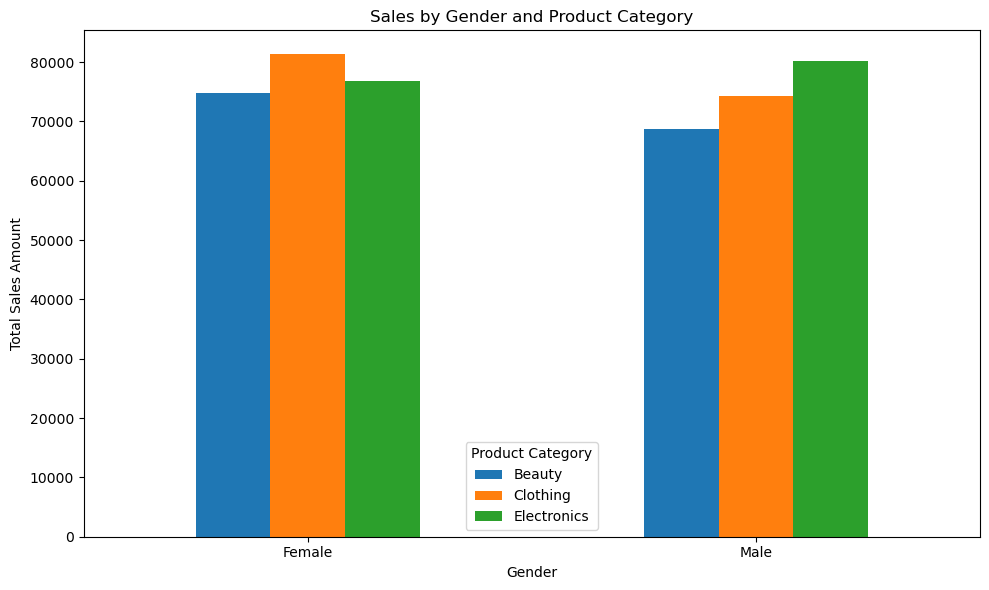

In [10]:
gender_category_sales.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Gender")
plt.ylabel("Total Sales Amount")
plt.title("Sales by Gender and Product Category")

plt.xticks(rotation=0)
plt.legend(title="Product Category")

plt.tight_layout()
plt.show()

In [11]:
print("========== SALES SUMMARY ==========")

print("\nTotal Sales:")
print(df["Total Amount"].sum())

print("\nSales by Product Category:")
print(category_sales)

print("\nTop Performing Category:")
print(category_sales.idxmax())

print("\nHighest Sales:")
print(category_sales.max())

========== SALES SUMMARY ==========

Total Sales:
456000

Sales by Product Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Top Performing Category:
Electronics

Highest Sales:
156905
